In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
predict = pd.read_csv("/Users/jordan/Documents/Epochs/source_inject/smiles_survey/smiles_survey_nn_predictions.csv")
true = pd.read_csv("/Users/jordan/Documents/Epochs/source_inject/smiles_survey/smiles_survey_mock_cat.csv")

Index(['StellarMass', 'SFR10', 'AGNlum', 'UV1500', 'UV1500AGN'], dtype='str')
100000
100000
100000
100000
100000


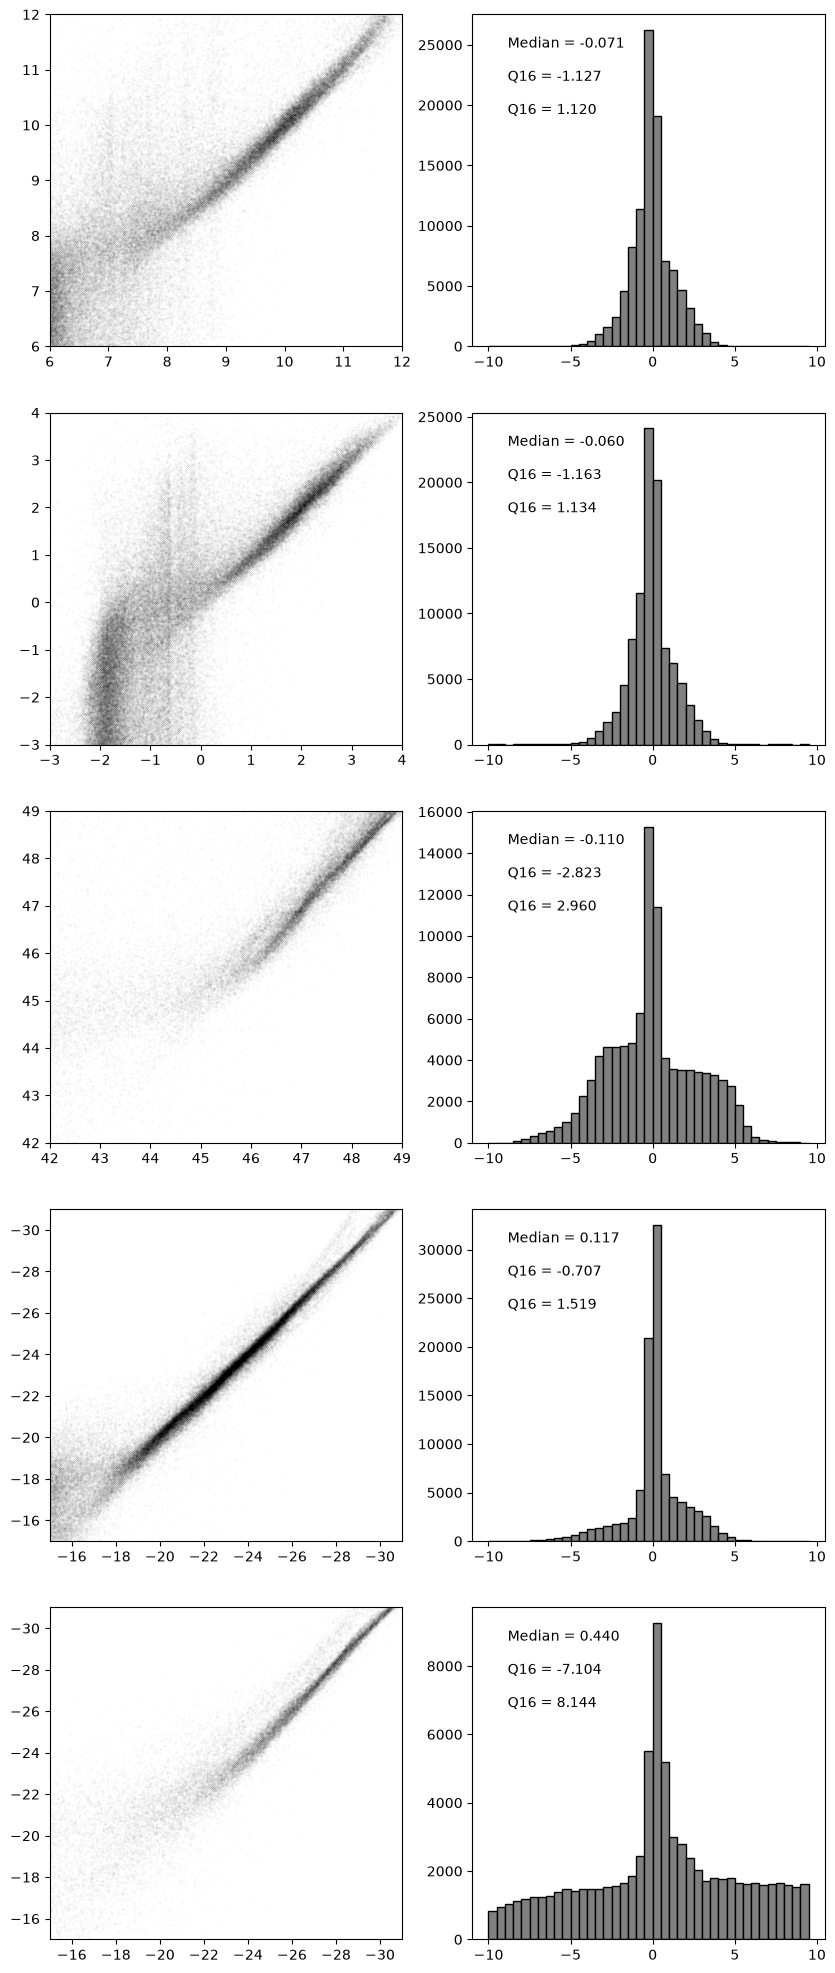

In [93]:
print(predict.columns)

fig, axs = plt.subplots(nrows=len(predict.columns), ncols=2, figsize = (10,25))
for kk in (0,1):
    for i, ax in enumerate(axs[:,kk]):

        # x = predict[predict.columns[i]][true["z"] <= 12]
        # y = true[predict.columns[i]][true["z"] <= 12]
        x = predict[predict.columns[i]]
        y = true[predict.columns[i]]
        
        if i <= 2:
                x = np.log10(x)
                y = np.log10(y)

        if i == 0:
            xmin = 6
            xmax = 12
        elif i == 1:
            xmin = -3
            xmax = 4
        elif i == 2:
            xmin = 42
            xmax = 49
        else:
            xmin = -15
            xmax = -31

        if kk == 0:
            ax.scatter(
                x,
                y,
                marker = '.',
                s = 0.1,
                alpha = 0.1,
                color = "black"
            )

            ax.set_xlim([xmin, xmax])
            ax.set_ylim([xmin, xmax])
        else:
            diff_ = x-y
            # diff_ = diff_[abs(diff_) <= 0.5]
            print(len(diff_))
            ax.hist(
                diff_,
                bins = np.arange(-10, 10, 0.5),
                edgecolor = "black",
                facecolor = "grey"
            )
            med_ = np.median( diff_ )
            q16_ = np.quantile(diff_, 0.16)
            q84_ = np.quantile(diff_, 0.84)

            ax.text(
                0.1, 0.9,
                f"Median = {med_:.3f}",
                transform = ax.transAxes
            )
            ax.text(
                0.1, 0.8,
                f"Q16 = {q16_:.3f}",
                transform = ax.transAxes
            )
            ax.text(
                0.1, 0.7,
                f"Q16 = {q84_:.3f}",
                transform = ax.transAxes
            )